# Hands-On 1: Tensor de condutividade 2D
**CAP-422 · Física Matemática Computacional (INPE)** · de um array de números a um objeto físico

Em um material anisotrópico, a densidade de corrente $\mathbf{J}$ e o campo elétrico $\mathbf{E}$ se relacionam por

$$\mathbf{J} = \boldsymbol{\sigma}\,\mathbf{E},\qquad
\boldsymbol{\sigma}=\begin{pmatrix}\sigma_x&0\\0&\sigma_y\end{pmatrix},\qquad
\boldsymbol{\sigma}'=R(\theta)\,\boldsymbol{\sigma}\,R(\theta)^{T},\qquad
R(\theta)=\begin{pmatrix}\cos\theta&-\sin\theta\\ \sin\theta&\cos\theta\end{pmatrix}.$$

> **Convenção.** O slide usa $\sigma' = R\sigma R^T$ (o tensor girado de $\theta$). Se você girar os *eixos* de $\theta$, as componentes nos novos eixos são $R^T\sigma R$, que é a mesma coisa com $\theta \to -\theta$. A física não muda, só o sinal do ângulo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from cap422 import tensors2d as t
from cap422.plots import plot_deviation, plot_vectors_and_ellipse

sp.init_printing(use_unicode=True)

ModuleNotFoundError: No module named 'matplotlib'

## 1. Definir $\boldsymbol\sigma$ simbolicamente

In [2]:
sigma = t.sigma_symbolic()
sigma

⎡σₓ   0 ⎤
⎢       ⎥
⎣0   σ_y⎦

## 2. Matriz de rotação e $\boldsymbol\sigma'(\theta)$

In [3]:
R = t.rotation_matrix()
sigma_p = t.rotated_sigma(sigma)
display(R)
sigma_p

⎡cos(θ)  -sin(θ)⎤
⎢               ⎥
⎣sin(θ)  cos(θ) ⎦

⎡      2             2       (σₓ - σ_y)⋅sin(2⋅θ)   ⎤
⎢σₓ⋅cos (θ) + σ_y⋅sin (θ)    ───────────────────   ⎥
⎢                                     2            ⎥
⎢                                                  ⎥
⎢  (σₓ - σ_y)⋅sin(2⋅θ)           2             2   ⎥
⎢  ───────────────────     σₓ⋅sin (θ) + σ_y⋅cos (θ)⎥
⎣           2                                      ⎦

## 3. Simplificação
Com ângulo duplo ($\cos^2\theta=\tfrac{1+\cos2\theta}{2}$, $\sin\theta\cos\theta=\tfrac{\sin2\theta}{2}$):

$$\sigma'=\frac{\sigma_x+\sigma_y}{2}\,I+\frac{\sigma_x-\sigma_y}{2}\begin{pmatrix}\cos2\theta&\sin2\theta\\ \sin2\theta&-\cos2\theta\end{pmatrix}$$

A parte isotrópica (a média) **não depende de $\theta$**; só a parte anisotrópica gira, e gira com $2\theta$.

In [4]:
sigma_p2 = t.rotated_sigma_double_angle()
display(sigma_p2)
print("Igual à forma anterior?", sp.simplify(sigma_p - sigma_p2) == sp.zeros(2))

⎡σₓ   σ_y   ⎛σₓ   σ_y⎞                ⎛σₓ   σ_y⎞               ⎤
⎢── + ─── + ⎜── - ───⎟⋅cos(2⋅θ)       ⎜── - ───⎟⋅sin(2⋅θ)      ⎥
⎢2     2    ⎝2     2 ⎠                ⎝2     2 ⎠               ⎥
⎢                                                              ⎥
⎢     ⎛σₓ   σ_y⎞                 σₓ   σ_y   ⎛σₓ   σ_y⎞         ⎥
⎢     ⎜── - ───⎟⋅sin(2⋅θ)        ── + ─── - ⎜── - ───⎟⋅cos(2⋅θ)⎥
⎣     ⎝2     2 ⎠                 2     2    ⎝2     2 ⎠         ⎦

Igual à forma anterior? True


## 4. Invariantes: $\mathrm{tr}(\sigma')=\mathrm{tr}(\sigma)$ e $\det(\sigma')=\det(\sigma)$

In [5]:
d_tr, d_det = t.invariants_difference(sigma, sigma_p)
print("tr(σ') - tr(σ)   =", d_tr)
print("det(σ') - det(σ) =", d_det)
print("tr  =", sp.simplify(sigma_p.trace()), "   det =", sp.simplify(sigma_p.det()))

tr(σ') - tr(σ)   = 0
det(σ') - det(σ) = 0
tr  = sigma_x + sigma_y    det = sigma_x*sigma_y


## 5. Valores numéricos com NumPy ($\sigma_x=2$, $\sigma_y=1$)

In [6]:
SX, SY = 2.0, 1.0
for th in (0, 30, 45):
    S = t.sigma_numeric(SX, SY, th)
    print(f"θ = {th}°   tr = {np.trace(S):.4f}   det = {np.linalg.det(S):.4f}")
    print(np.round(S, 4), "\n")

θ = 0°   tr = 3.0000   det = 2.0000
[[2. 0.]
 [0. 1.]] 

θ = 30°   tr = 3.0000   det = 2.0000
[[1.75  0.433]
 [0.433 1.25 ]] 

θ = 45°   tr = 3.0000   det = 2.0000
[[1.5 0.5]
 [0.5 1.5]] 



## 6. $\mathbf{J}=\boldsymbol\sigma'\mathbf{E}$ com $\mathbf{E}=(1,1)$

In [7]:
E = np.array([1.0, 1.0])
for th in (0, 30, 45):
    S = t.sigma_numeric(SX, SY, th)
    J = t.current_density(S, E)
    print(f"θ = {th:>2}°   J = {np.round(J, 4)}   ângulo de E para J = {t.angle_between_deg(E, J):+.2f}°")

θ =  0°   J = [2. 1.]   ângulo de E para J = -18.43°
θ = 30°   J = [2.183 1.683]   ângulo de E para J = -7.37°
θ = 45°   J = [2. 2.]   ângulo de E para J = +0.00°


Em $\theta=45^\circ$, $\mathbf{J}=(2,2)=2\,\mathbf{E}$. O vetor $(1,1)$ é **autovetor** de $\sigma'$ (autovalor $\sigma_x=2$), e é por isso que $\mathbf J\parallel\mathbf E$ ali.

## 7. Visualização
*Em cima:* setas de $\mathbf E$ (tracejadas) e $\mathbf J$ (cheias) para $\mathbf E_1,\mathbf E_2,\mathbf E_3$; a elipse é a imagem do círculo unitário por $\sigma'$ (é a "geometria da rotação" do slide).
*Embaixo:* $|\mathbf J|$ em função da direção de $\mathbf E$ (polar).

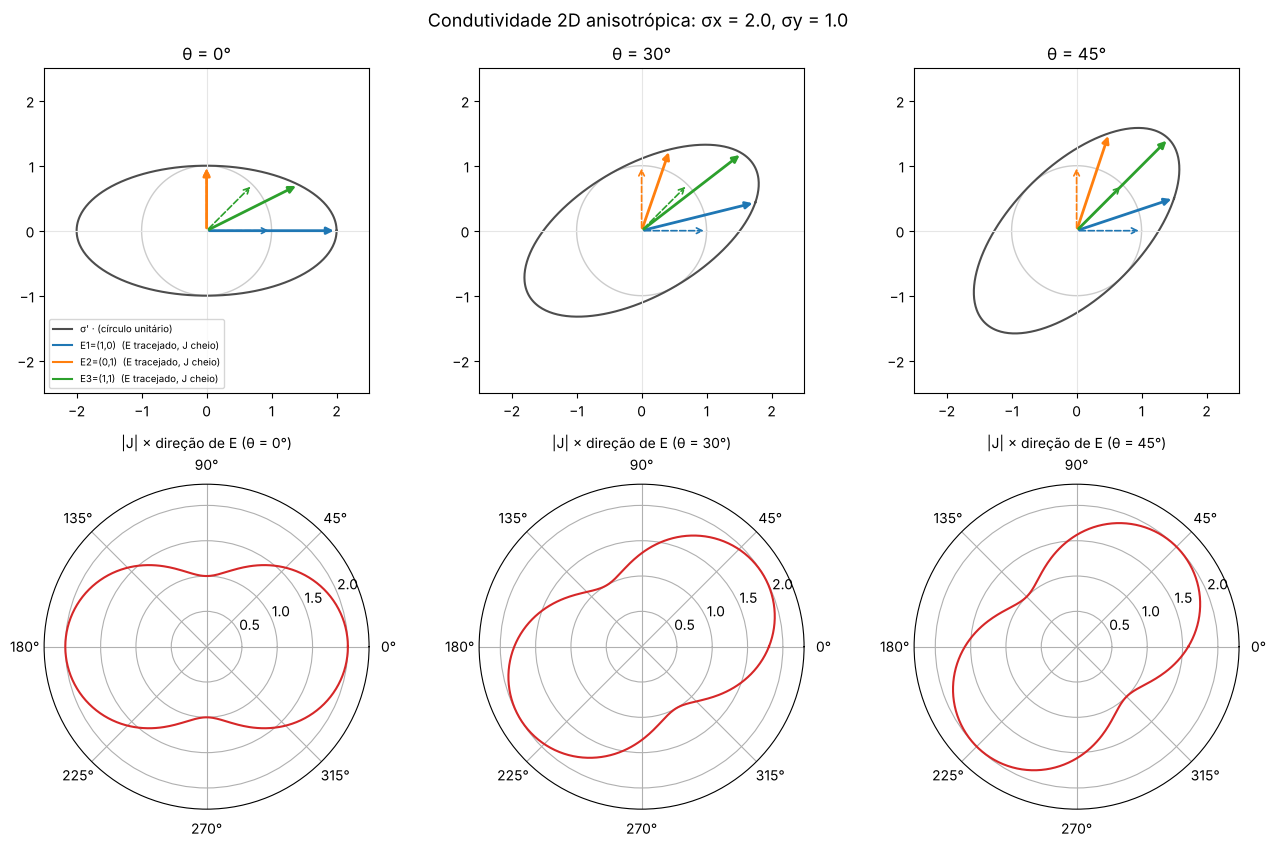

In [8]:
fig1 = plot_vectors_and_ellipse(SX, SY, (0, 30, 45), savepath="outputs/J_vs_E.png")
plt.show()

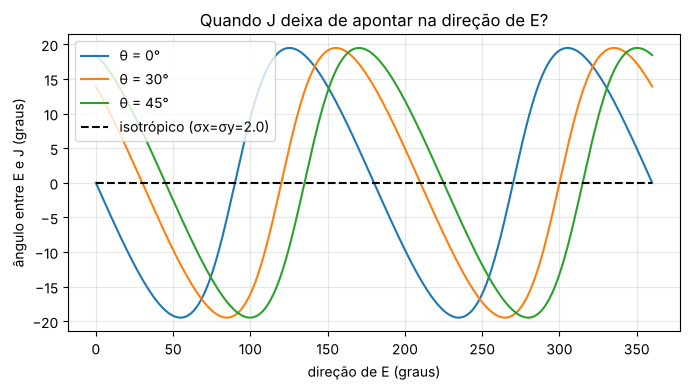

Desvio máximo teórico entre J e E: 19.47 graus


In [9]:
fig2 = plot_deviation(SX, SY, (0, 30, 45), savepath="outputs/desvio_E_J.png")
plt.show()
print("Desvio máximo teórico entre J e E:",
      round(float(np.degrees(np.arcsin((SX - SY) / (SX + SY)))), 2), "graus")

## Perguntas para discussão

**1. Quais componentes de $\sigma$ mudam com a rotação? Quais permanecem?**
$\sigma'_{xx}$, $\sigma'_{yy}$ e $\sigma'_{xy}=\sigma'_{yx}$ dependem de $\theta$. Em $\theta=0$ (ou $180^\circ$) tudo igual; em $\theta=90^\circ$ os termos diagonais trocam ($\sigma'_{xx}=\sigma_y$, $\sigma'_{yy}=\sigma_x$). No caso isotrópico ($\sigma_x=\sigma_y$) nenhuma componente muda. A soma $\sigma'_{xx}+\sigma'_{yy}$ também nunca muda.

**2. Quais grandezas são invariantes? Por quê?**
O traço, o determinante (e portanto os autovalores $\sigma_x,\sigma_y$). Como $R^T=R^{-1}$, $\sigma'=R\sigma R^{-1}$ é uma transformação de similaridade: $\det(R\sigma R^T)=\det R\,\det\sigma\,\det R^T=\det\sigma$ e $\mathrm{tr}(R\sigma R^T)=\mathrm{tr}(\sigma R^TR)=\mathrm{tr}\,\sigma$ (propriedade cíclica do traço).

**3. Como a direção de $\mathbf J$ se compara com a de $\mathbf E$ no caso anisotrópico?**
Em geral **não são paralelos**. $\mathbf J\parallel\mathbf E$ só quando $\mathbf E$ está sobre um eixo principal (autovetor de $\sigma'$). Fora disso, $\mathbf J$ é "puxado" para a direção de maior condutividade. O desvio máximo é $\arcsin\frac{\sigma_x-\sigma_y}{\sigma_x+\sigma_y}\approx19{,}5^\circ$ para $(2,1)$, como no gráfico.

**4. O que acontece quando $\sigma_x=\sigma_y$? Qual a relação com isotropia?**
$\sigma'=\sigma_x I$ para qualquer $\theta$, então $\mathbf J=\sigma_x\mathbf E$ sempre paralelo e a elipse vira círculo. **Isotropia = invariância por rotação** (o tensor é um múltiplo da identidade).

**5. Por que a matriz de condutividade é mais do que um array de números?**
Porque os números só têm sentido junto com a **base** em que foram escritos e com a **lei de transformação** $\sigma'=R\sigma R^T$ que diz como mudam quando a base muda. O objeto físico (a aplicação linear $\mathbf E\mapsto\mathbf J$) é o mesmo em qualquer base; as componentes são só uma representação. Um array qualquer, sem essa lei, não é tensor. É isso que o curso vai formalizar com $V\otimes V^*$.